<a href="https://colab.research.google.com/github/JFish72/CSC-349-Machine-Learning-/blob/main/HW7/wine_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Task One:**
*   Repeating the same process as the last assignment, the wine dataset can me directly imported from Scikit learn. This is a much smoother process compared to searching for and then downloading outside datasets in the form of CSV files.  
*   For this step, I am simply placing the information from the dataset into a pandas DataFrame, returning the datasets dimensions, creating a statistical summary, and checking for missing values.
*   To prepare our data for further tasks and computation, it is best to scale our data to prevent large numerical differences from holding too much weight in our models. To display the difference that the StandardScaler can make to the feature spread, I am using two boxplots.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

wine = load_wine()

X = pd.DataFrame(wine.data, columns = wine.feature_names)
y = wine.target

print("Dataset Dimensions:", X.shape)
print("Statistical Summary:\n", X.describe().round(2).to_string())
print("Missing Values:\n", X.isnull().sum().to_string())


Dataset Dimensions: (178, 13)
Statistical Summary:
        alcohol  malic_acid     ash  alcalinity_of_ash  magnesium  total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity     hue  od280/od315_of_diluted_wines  proline
count   178.00      178.00  178.00             178.00     178.00         178.00      178.00                178.00           178.00           178.00  178.00                        178.00   178.00
mean     13.00        2.34    2.37              19.49      99.74           2.30        2.03                  0.36             1.59             5.06    0.96                          2.61   746.89
std       0.81        1.12    0.27               3.34      14.28           0.63        1.00                  0.12             0.57             2.32    0.23                          0.71   314.91
min      11.03        0.74    1.36              10.60      70.00           0.98        0.34                  0.13             0.41             1.28    0.48             

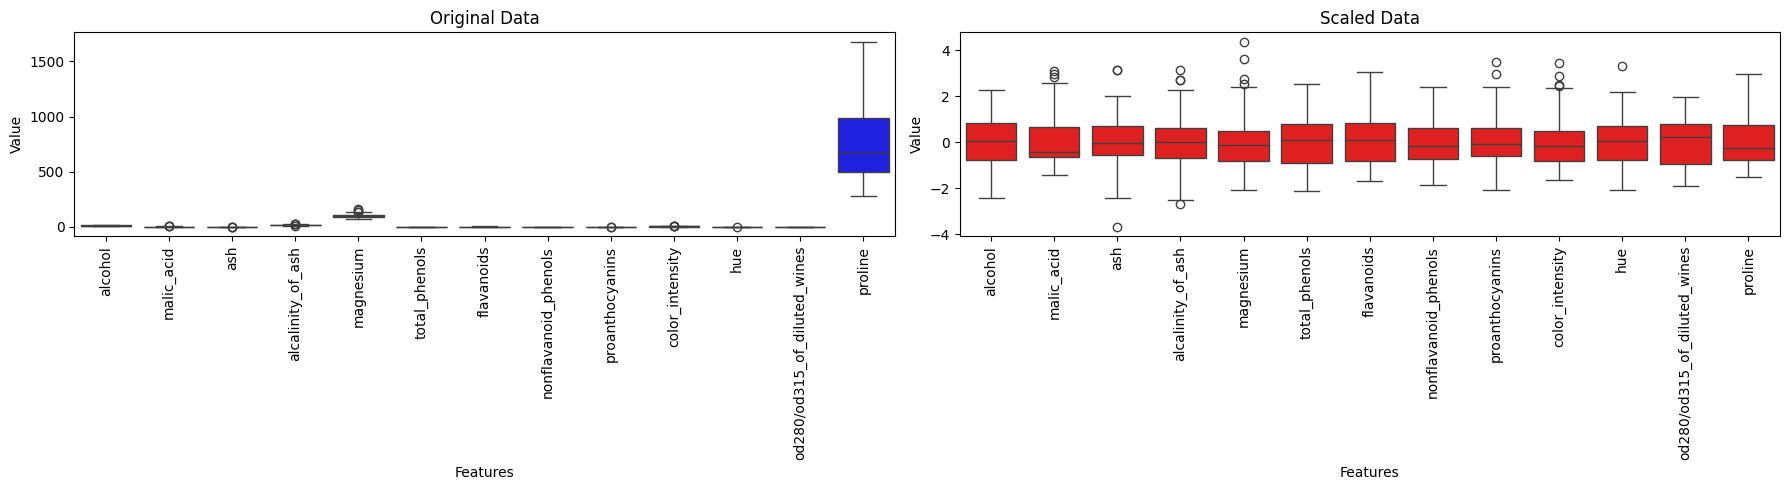

In [ ]:
X_scaled = StandardScaler().fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns = X.columns)

fig, axes = plt.subplots(1, 2, figsize = (18, 5))

sns.boxplot(data = X, ax = axes[0], color = 'blue')
sns.boxplot(data = X_scaled_df, ax = axes[1], color = 'red')

axes[0].set_title('Original Data')
axes[1].set_title('Scaled Data')

for ax in axes:
    ax.tick_params(axis = 'x', rotation = 90)
    ax.set_xlabel('Features')
    ax.set_ylabel('Value')

plt.tight_layout()
plt.show()



**Task Two:**
*   To illustrate the difference that the hyperparameter k can create, I am iterating from 1 to 10 and displaying the changes in the model. The inertia value measures the squared distance within a cluster and will create my elbow curve. The silhouette score examines the in-cluster cohesion in comparison to the other clusters around it. Since there is a comparison being made, in this task, k = 1 will not have a silhouette score.
*   After all iterations are complete, it is important to see which method suggests which k value. To highlight this choice and the explanation behind it, I will plot the points for a better visual representation.  


Elbow Method Suggested K: 3
Silhouette Method Suggested K: 3


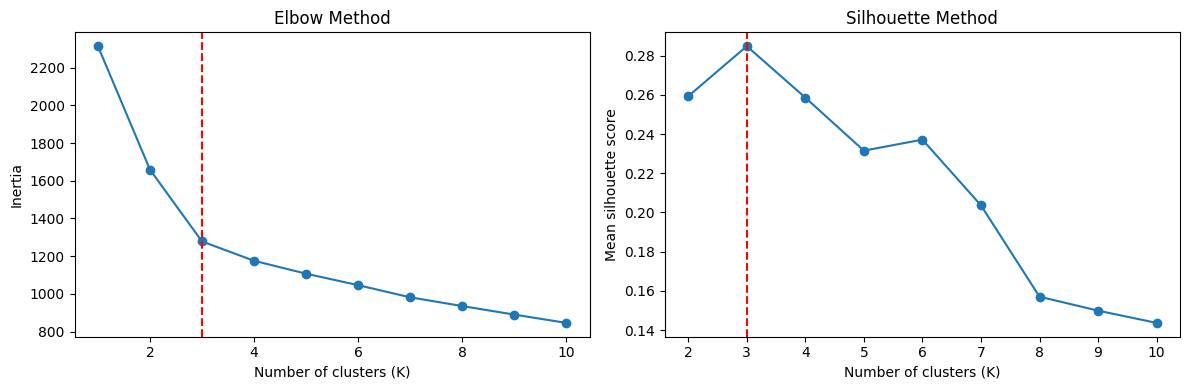

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertias = []
silhouette_scores = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters = k, random_state = 42, n_init = 20)
    labels = kmeans.fit_predict(X_scaled)
    inertias.append(kmeans.inertia_)
    if k >= 2:
        silhouette_scores.append(silhouette_score(X_scaled, labels))

points = np.column_stack((np.arange(1, 11), inertias)).astype(float)
scaled_points = (points - points.min(axis = 0)) / (points.max(axis = 0) - points.min(axis = 0))

start = scaled_points[0]
end = scaled_points[-1]

direction = end - start

distances = np.abs(direction[0] * (scaled_points[:, 1] - start[1]) - direction[1] * (scaled_points[:, 0] - start[0])) / np.linalg.norm(direction)

ks = np.arange(1, 11)

elbow_k = int((ks)[np.argmax(distances)])
silhouette_k = int(ks[1:][np.argmax(silhouette_scores)])

print("Elbow Method Suggested K:", elbow_k)
print("Silhouette Method Suggested K:", silhouette_k)

fig, axes = plt.subplots(1, 2, figsize = (12,4))
axes[0].plot(ks, inertias, 'o-'); axes[0].axvline(elbow_k, color = 'red', linestyle = '--')
axes[0].set(title = 'Elbow Method', xlabel = 'Number of clusters (K)', ylabel = 'Inertia')
axes[1].plot(ks[1:], silhouette_scores, 'o-'); axes[1].axvline(silhouette_k, color = 'red', linestyle = '--')
axes[1].set(title = 'Silhouette Method', xlabel = 'Number of clusters (K)', ylabel = 'Mean silhouette score')

plt.tight_layout()
plt.show()

**Task Three:**
*   To reduce the 13 original features of the dataset to two principal components, I have to perform PCA. Using a new K-means model with k set to 3, which, from above, is the most efficient number of clusters.
*   The Voronoi diagram partitions the regions closest to each of the centroids. On the diagram, sample points are organized by color with the centroids marked separately.

